# DEMO - Visual anomaly detection on LUMI

## Evaluating and fine tuning AnomalyCLIP on LUMI

This demo is set up to showcase a simple pipeline of dataset inspection and processing, model evaluation and model fine-tuning for a visual anomaly detection model workflow. 
The model we will be working with today is AnomalyCLIP. The dataset chosen for the demo is the Real-IAD dataset. We will only work with a subset of the dataset today so mainly demonstrate the workflow. 

For more information of the model, you can visit [AnomalCLIP](https://github.com/zqhang/AnomalyCLIP). 
For more information of the dataset, you can visit [Real-IAD dataset](https://realiad4ad.github.io/Real-IAD/)

The demo will include 3 phases: 

- Phase 0: Setting up dataset and environment.
- Phase 1: Evaluate the VisA checkpoint on a held-out Real-IAD split. 
- Phase 2: Fine-tune on Real-IAD, re-evaluate, compare.

**IMPORTANT NOTE**: Only run the following codeblock once to create the virtual environment

In [ ]:
%%bash
python3 -m venv .venv

### Phase 0: Setting up dataset and environment

As we are utilizing the container premade by LUMI AI Factory `lumi-multitorch`, most of the basic packages are already pre-installed and can be imported directly.

In [ ]:
import argparse
import os
import sys
import time
import torch
import pandas as pd
from pathlib import Path
import json, random, shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In the case that we need any additional packages that are not pre-installed, we can create our own virtual environment to install packages upon the given container `lumi-multitorch`.
It is important to remember that since we are using jupyter notebook environment, the container was already loaded. However, in the case of submitting separating SLURM job, you will need to load the container and then install the packages after the container is loaded. 

In [ ]:
%%bash
source .venv/bin/activate
which pip
pip install ftfy regex tabulate scikit-image

In [ ]:
# Printing out the LUMI project we are using and under which user account we are using

SLURM_JOB_ACCOUNT = os.getenv("SLURM_JOB_ACCOUNT")
USER = os.getenv("SLURM_JOB_USER")

print(f"Billing project:  {SLURM_JOB_ACCOUNT}")
print(f"Username:         {USER}")

Billing project:  project_462000131
Username:         mainguye


Now we will set up where the output destination for our tuned model and evaluation result

In [ ]:
# Name of our model
input_model = "AnomalyCLIP"

output_path = os.path.join(os.getcwd(), "ft_model")                        # All outputs are saved next to the notebooks
model_output_name = f"{input_model.split('/')[-1]}_finetuned"

num_workers = int(os.getenv("SLURM_CPUS_PER_TASK"))

# Output model 
output_model_dir = os.path.join(output_path, model_output_name)
merged_output_dir = os.path.join(
    output_path,
    f"{model_output_name}_merged"
)

print(f"Model will be saved to: {merged_output_dir}")

Model will be saved to: /pfs/lustrep4/scratch/project_462000131/mainguye/demo/visual-anomaly-detection-demo/ft_model/AnomalyCLIP_finetuned_merged


#### Cloning the AnomalyCLIP repository

The authors of the AnomalyCLIP mode have provided us with evaluation and training script in the open source repository. We can directly clone the repository to work with the given codebase. 
For major foundational model nowadays (for example, large language models), the majority of the models can also be found through HuggingFace. However, for other type of models, you will usually find them available through the authors' open source repository. 

For more information on how to do inference and fine-tuning models from HuggingFace, you can take a look at: 
- [HuggingFace's documentations on Transformers-based models](https://huggingface.co/docs/transformers/v5.24.1/en/index)
- [CSC's guide and example on how to fine-tune LLMs](https://github.com/CSCfi/llm-fine-tuning-examples)
- [CSC's guide and example on how to do LLM inference](https://github.com/CSCfi/ai-inference-examples)

In [ ]:
%%bash
git clone https://github.com/zqhang/AnomalyCLIP.git

Cloning into 'AnomalyCLIP'...
remote: Enumerating objects: 307, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (66/66), done.
remote: Total 307 (delta 126), reused 96 (delta 96), pack-reused 145 (from 1)
Receiving objects: 100% (307/307), 56.90 MiB | 31.70 MiB/s, done.
Resolving deltas: 100% (149/149), done.
Updating files: 100% (106/106), done.


The original AnomalyCLIP repository contains training script, dataset loading script and model loading script hard coded other type of datasets. We have provided here the altered code that will work with our subset of Real-IAD dataset.

In [ ]:
%%bash
mkdir AnomalyCLIP_backup/
mv AnomalyCLIP/train.py AnomalyCLIP_backup/train.py
mv AnomalyCLIP/dataset.py AnomalyCLIP_backup/dataset.py
mv AnomalyCLIP/AnomalyCLIP_lib/model_load.py AnomalyCLIP_backup/model_load.py

cp scripts/train.py AnomalyCLIP/train.py
cp scripts/dataset.py AnomalyCLIP/dataset.py
cp scripts/model_load.py AnomalyCLIP/AnomalyCLIP_lib/model_load.py

#### Dataset inspection - subset of Real-IAD dataset

The given dataset is a subset of the Real-IAD dataset which is a set of images of the zipper as a product. 

In [ ]:
# Setting the variables for the dataset path

dataset_root = Path("dataset")
images_dir, jsons_dir = dataset_root / "realiad_1024", dataset_root / "realiad_jsons_sv"
out_dir = Path("dataset/data/all")

In [35]:
def to_record(it, prefix, origin):
    ok = it["anomaly_class"] == "OK"
    mask = it.get("mask_path")
    return dict(
        img_path=str(images_dir / prefix / it["image_path"]),
        mask_path=str(images_dir / prefix / mask) if (mask and not ok) else "",
        cls_name=it["category"],
        specie_name="" if ok else it["anomaly_class"],
        anomaly=0 if ok else 1,
        origin=origin)            # original Real-IAD split, kept for the later split step

pool = {}
for jf in sorted(jsons_dir.glob("*.json")):
    with open(jf) as f:
        d = json.load(f)
    prefix = d["meta"]["prefix"]
    pool[jf.stem] = [to_record(it, prefix, o) for o in ("train", "test") for it in d[o]]

out_dir.mkdir(parents=True, exist_ok=True)
with open(out_dir / "meta.json", "w") as f:
    json.dump({"train": {}, "test": pool}, f)

for cls, recs in pool.items():
    n_ano = sum(r["anomaly"] for r in recs)
    n_tr = sum(r["origin"] == "train" for r in recs)
    print(f"{cls}: total={len(recs)} normal={len(recs) - n_ano} anomalous={n_ano} (from json train={n_tr}, test={len(recs) - n_tr})")

audiojack: total=1010 normal=797 anomalous=213 (from json train=399, test=611)
toothbrush: total=1001 normal=545 anomalous=456 (from json train=273, test=728)
zipper: total=1001 normal=501 anomalous=500 (from json train=251, test=750)


Before going further with the dataset splitting, we want to take a quick look at how our dataset looks like. 
As Real-IAD is an image-based dataset with segmentation mask indicatingthe defect area, we will randomly showcase the different data sample to see how they will correspond visually.

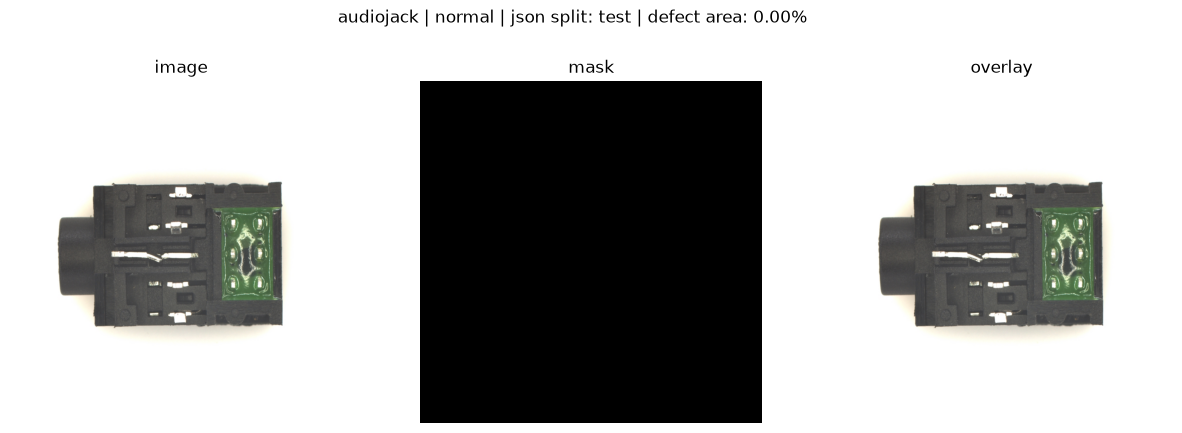

In [ ]:
# Inspecting the dataset - Randomizing the inspection process

with open("dataset/data/all/meta.json") as f:
    pool = json.load(f)["test"]

cls = random.choice(list(pool))
rec = random.choice(pool[cls])                       # normal or anomalous

img = np.array(Image.open(rec["img_path"]).convert("RGB"))
if rec["anomaly"]:
    mask = np.array(Image.open(rec["mask_path"]).convert("L")) > 0
    if mask.shape != img.shape[:2]:
        mask = np.array(Image.fromarray(mask.astype(np.uint8) * 255).resize(img.shape[1::-1], Image.NEAREST)) > 0
else:
    mask = np.zeros(img.shape[:2], bool)             # normal image: empty mask

overlay = img.copy()
overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, (img, mask, overlay), ("image", "mask", "overlay")):
    a.imshow(im, cmap="gray" if im.ndim == 2 else None); a.set_title(t); a.axis("off")
label = f"anomalous ({rec['specie_name']})" if rec["anomaly"] else "normal"
fig.suptitle(f"{cls} | {label} | json split: {rec['origin']} | defect area: {mask.mean():.2%}")
plt.show()

To effectively evaluate our future fine-tuned model, we need a test dataset. Thus, we will split our current dataset into 2 parts: training dataset and test dataset. 

This is because we don't want to evaluate the fine-tuned model with the same dataset we use for training. The model should be evaluated based on unseend dataset to avoid non-generalization. 

A good rule of thumb is to divide the dataset into 80% for training data and 20% for testing data or 90% for training data and 10% for testing data. 

In [ ]:
# Dataset splitting 

ratio_train = 0.8                 # fraction of each (class, normal/anomalous) group used for fine-tuning
seed = 0

dataset_root = Path("dataset")
images_dir = dataset_root / "realiad_1024"
out_root = Path("dataset/data")

with open("dataset/data/all/meta.json") as f:
    pool = json.load(f)["test"]

rng = random.Random(seed)
train, test = {}, {}
for cls, recs in pool.items():
    train[cls], test[cls] = [], []
    for label in (0, 1):               # stratify so both splits keep normal and anomalous images
        group = [r for r in recs if r["anomaly"] == label]
        rng.shuffle(group)
        k = round(len(group) * ratio_train)
        train[cls] += group[:k]
        test[cls] += group[k:]

def rel(p):
    # AnomalyCLIP opens os.path.join(root, path), so store paths relative to each split's root
    return str(Path("images") / Path(p).relative_to(images_dir)) if p else ""

def copy_file(src, root):
    dst = root / rel(src)
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

def to_anomalyclip(recs, root):
    out = []
    for r in recs:
        for p in (r["img_path"], r["mask_path"]):
            if p:
                copy_file(p, root)    
        out.append(dict(img_path=rel(r["img_path"]), mask_path=rel(r["mask_path"]), cls_name=r["cls_name"],
                        specie_name=r["specie_name"], anomaly=r["anomaly"]))
    return out

for name, split in (("realiad_ft", train), ("realiad_eval", test)):
    root = out_root / name
    root.mkdir(parents=True, exist_ok=True)
    meta = {"train": {}, "test": {c: to_anomalyclip(r, root) for c, r in split.items()}}   # Dataset reads the "test" key for both train.py and test.py
    with open(root / "meta.json", "w") as f:
        json.dump(meta, f)
    print(name, {c: (len(r), sum(x["anomaly"] for x in r)) for c, r in split.items()}, "(total, anomalous)")


realiad_ft {'audiojack': (808, 170), 'toothbrush': (801, 365), 'zipper': (801, 400)} (total, anomalous)
realiad_eval {'audiojack': (202, 43), 'toothbrush': (200, 91), 'zipper': (200, 100)} (total, anomalous)
realiad_ft unresolved paths: 0
realiad_eval unresolved paths: 0


In [ ]:
# Sanity check: every path must resolve exactly as AnomalyCLIP's Dataset will open it 

for name in ("realiad_ft", "realiad_eval"):
    root = out_root / name
    meta = json.load(open(root / "meta.json"))["test"]
    bad = [p for recs in meta.values() for r in recs for p in (r["img_path"], r["mask_path"])
           if p and not os.path.exists(os.path.join(root, p))]
    print(name, "unresolved paths:", len(bad))

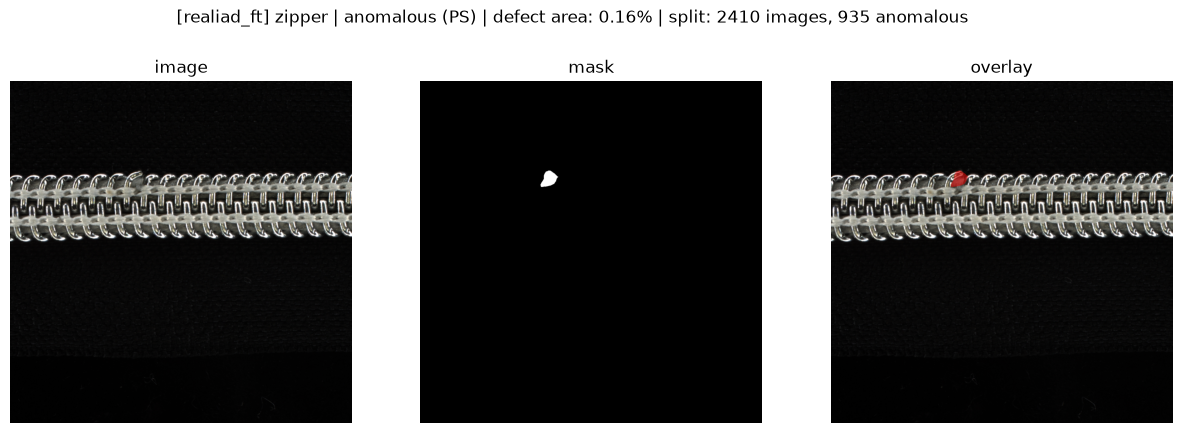

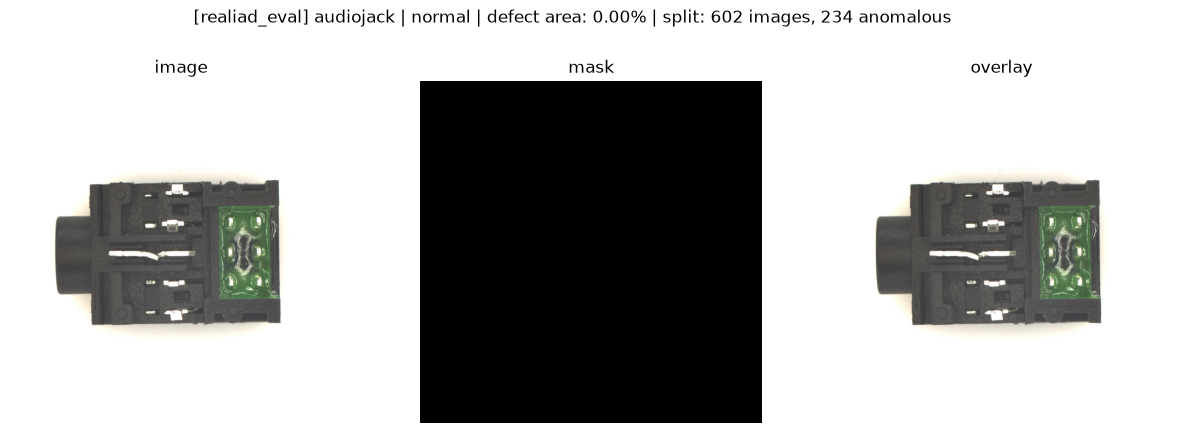

In [ ]:
# Check the images visually after the split
out_root = "dataset/data"
for name in ("realiad_ft", "realiad_eval"):
    root = os.path.join(out_root, name)
    with open(os.path.join(root, "meta.json")) as f:
        meta = json.load(f)["test"]

    cls = random.choice(list(meta))
    rec = random.choice(meta[cls])                       # normal or anomalous

    # open files exactly as AnomalyCLIP's Dataset.__getitem__ does
    img = np.array(Image.open(os.path.join(root, rec["img_path"])).convert("RGB"))
    if rec["anomaly"]:
        mask = np.array(Image.open(os.path.join(root, rec["mask_path"])).convert("L")) > 0
    else:
        mask = np.zeros(img.shape[:2], bool)

    overlay = img.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

    n_img = sum(len(v) for v in meta.values())
    n_ano = sum(r["anomaly"] for v in meta.values() for r in v)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a, im, t in zip(ax, (img, mask, overlay), ("image", "mask", "overlay")):
        a.imshow(im, cmap="gray" if im.ndim == 2 else None); a.set_title(t); a.axis("off")
    label = f"anomalous ({rec['specie_name']})" if rec["anomaly"] else "normal"
    fig.suptitle(f"[{name}] {cls} | {label} | defect area: {mask.mean():.2%} | split: {n_img} images, {n_ano} anomalous")
    plt.show()

### Phase 1: Evaluate the VisA checkpoint on a held-out REAL-IAE split

In this demo, we will use the given script from AnomalyCLIP's authors to evaluate the model before fine-tuning

First, we will evaluate the given AnomalyCLIP's checkpoint to have our baseline for the model efficiency. 

With this result, we can use it to compare and evaluate if the fine-tuning is effective.

In [23]:
%%bash
source .venv/bin/activate
cd AnomalyCLIP
python test.py --dataset realiad --data_path ../dataset/data/realiad_eval \
  --save_path ../results/visa_zero_shot \
  --checkpoint_path ./checkpoints/9_12_4_multiscale/epoch_15.pth \
  --features_list 24 --image_size 518 --depth 9 --n_ctx 12 --t_n_ctx 4


Namespace(data_path='../dataset/data/realiad_eval', save_path='../results/visa_zero_shot', checkpoint_path='./checkpoints/9_12_4_multiscale/epoch_15.pth', dataset='realiad', features_list=[24], image_size=518, depth=9, n_ctx=12, t_n_ctx=4, feature_map_layer=[0, 1, 2, 3], metrics='image-pixel-level', seed=111, sigma=4)
name ViT-L/14@336px


100%|███████████████████████████████████████| 934M/934M [00:13<00:00, 68.0MiB/s]


text_layer False
text_layer True
Initializing class-specific contexts
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
embedding_pos torch.Size([1, 77, 768])
tokenized_prompts shape torch.Size([1, 1, 77]) torch.Size([1, 1, 77])


100%|██████████| 602/602 [01:25<00:00,  7.07it/s]
26-11-24 02:46:59.025 - INFO: 
| objects    |   pixel_auroc |   pixel_aupro |   image_auroc |   image_ap |
|:-----------|--------------:|--------------:|--------------:|-----------:|
| audiojack  |          96.8 |          79.6 |          71.5 |       46.1 |
| toothbrush |          92.1 |          79.3 |          68.1 |       64.3 |
| zipper     |          88.6 |          65.5 |          89.2 |       91.8 |
| mean       |          92.5 |          74.8 |          76.3 |       67.4 |


### Phase 2: Fine tuning the AnomalyCLIP model with the dataset

In this demo, we will use the given script from AnomalyCLIP's authors to fine-tune the model as well

In [29]:
%%bash
source .venv/bin/activate
cd AnomalyCLIP
python train.py --dataset realiad --train_data_path ../dataset/data/realiad_ft \
  --save_path ./checkpoints/realiad_ft \
  --checkpoint_path ./checkpoints/9_12_4_multiscale/epoch_15.pth \
  --features_list 24 --image_size 518 --batch_size 64 --depth 9 --n_ctx 12 --t_n_ctx 4 \
  --epoch 2 --learning_rate 0.0001

name ViT-L/14@336px
text_layer False
text_layer True
Initializing class-specific contexts
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
embedding_pos torch.Size([1, 77, 768])
tokenized_prompts shape torch.Size([1, 1, 77]) torch.Size([1, 1, 77])


100%|██████████| 38/38 [04:15<00:00,  6.71s/it]
26-11-24 03:02:47.803 - INFO: epoch [1/2], loss:3.8770, image_loss:1.0071
100%|██████████| 38/38 [03:59<00:00,  6.29s/it]
26-11-24 03:06:46.869 - INFO: epoch [2/2], loss:3.8799, image_loss:0.5725
100%|██████████| 2/2 [08:14<00:00, 247.10s/it]


And now we will run the new evaluation but on our fine-tuned model checkpoint to evaluate the fine-tuning process.

In [31]:
%%bash
source .venv/bin/activate
cd AnomalyCLIP
python test.py --dataset realiad --data_path ../dataset/data/realiad_eval \
  --save_path ../results/realiad_finetuned \
  --checkpoint_path ./checkpoints/realiad_ft/epoch_2.pth \
  --features_list 24 --image_size 518 --depth 9 --n_ctx 12 --t_n_ctx 4

Namespace(data_path='../dataset/data/realiad_eval', save_path='../results/realiad_finetuned', checkpoint_path='./checkpoints/realiad_ft/epoch_2.pth', dataset='realiad', features_list=[24], image_size=518, depth=9, n_ctx=12, t_n_ctx=4, feature_map_layer=[0, 1, 2, 3], metrics='image-pixel-level', seed=111, sigma=4)
name ViT-L/14@336px
text_layer False
text_layer True
Initializing class-specific contexts
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
single_para torch.Size([4, 768])
embedding_pos torch.Size([1, 77, 768])
tokenized_prompts shape torch.Size([1, 1, 77]) torch.Size([1, 1, 77])


100%|██████████| 602/602 [01:07<00:00,  8.88it/s]
26-11-24 03:17:15.783 - INFO: 
| objects    |   pixel_auroc |   pixel_aupro |   image_auroc |   image_ap |
|:-----------|--------------:|--------------:|--------------:|-----------:|
| audiojack  |          96.7 |          75.7 |          73.9 |       50.4 |
| toothbrush |          93.4 |          81.8 |          74.1 |       70.5 |
| zipper     |          89.1 |          71.8 |          89.9 |       92.5 |
| mean       |          93.1 |          76.4 |          79.3 |       71.1 |


### And...You have done it!

You can now move on to more advanced level for model training and fine-tuning. 